# Predicting monthly tourist arrivals to Sri Lanka

I predict monthly tourist arrivals from each origin market to help with tourism planning. The data comes from nine official [SLTDA Excel files](https://www.sltda.gov.lk/en/tourist-arrivals-from-all-countries), covering 2018 to September 2026.

I standardised clear country-name variations, kept genuine zeros and removed unresolved entries and rows without enough history. The available monthly country totals match the published national totals.

## Setup
Run the install cell first. In Colab, upload `Tourism_Arrivals.csv` when prompted. Locally, the notebook uses the CSV in the repo’s data folder; a CSV beside the notebook also works. Restart the runtime if asked, then run the cells in order.

In [1]:
%pip install -q pandas numpy matplotlib "scikit-learn>=1.4" shap lime

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.ensemble import ExtraTreesRegressor, VotingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

csv_file = next((path for path in [Path('../data/Tourism_Arrivals.csv'),
                                 Path('data/Tourism_Arrivals.csv'),
                                 Path('Tourism_Arrivals.csv')] if path.exists()), None)
if csv_file is None:
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError('Place Tourism_Arrivals.csv in data/ or beside the notebook.')
    files.upload()
    csv_file = Path('Tourism_Arrivals.csv')

data = pd.read_csv(csv_file)
data['Month'] = pd.PeriodIndex(data.Year_Month, freq='M')
features = ['Country', 'lag_1', 'lag_2', 'lag_3', 'lag_12', 'month_number']
random_seed = 42

assert not data.isna().any().any()
assert not data.duplicated(['Year_Month', 'Country']).any()
assert data[[column for column in features if column != 'Country'] + ['Arrivals']].ge(0).all().all()
display(data.head())

,Year_Month,Country,lag_1,lag_2,lag_3,lag_12,month_number,Arrivals,Month
0,2019-01,Afghanistan,72,52,41,83,1,49,2019-01
1,2019-01,Albania,31,12,13,14,1,48,2019-01
2,2019-01,Algeria,43,27,20,38,1,34,2019-01
3,2019-01,Andorra,4,1,3,4,1,2,2019-01
4,2019-01,Angola,1,1,1,0,1,4,2019-01


## Inputs and time split
I use the country, target month and arrivals 1, 2, 3 and 12 months earlier. For January 2024, `lag_1` is December 2023 and `lag_12` is January 2023. The first year supplies the annual lag, so modelling starts in 2019.

I train on 2019–2023 and compare models on 2024 development data. The later period was inspected during earlier experiments, so it is not an untouched test set.

Origins without training examples: ['Aruba', 'Central African Republic', 'Guinea', 'Palau']
Training rows: 10811 | validation rows: 2207


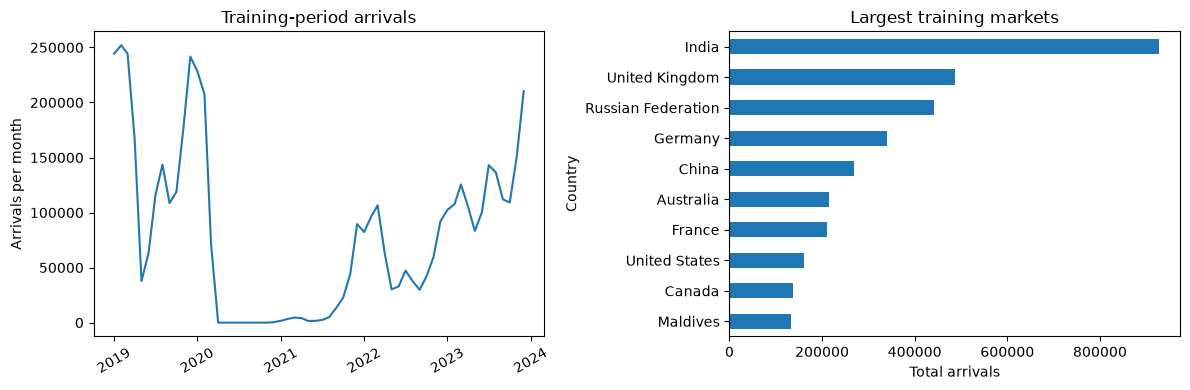

,Arrivals
count,10811.000000
mean,446.107853
std,2252.160959
min,0.000000
25%,0.000000
50%,3.000000
75%,72.000000
max,48442.000000


In [3]:
# I keep earlier months for training rather than shuffle the rows.
train_data = data.loc[data.Month.dt.year.between(2019, 2023)].copy()
validation_data = data.loc[data.Month.dt.year.eq(2024)].copy()
known_countries = set(train_data.Country)
print('Origins without training examples:', sorted(set(validation_data.Country) - known_countries))
# I only evaluate origins that have training examples.
validation_data = validation_data.loc[validation_data.Country.isin(known_countries)].copy()

assert train_data.Month.max() < validation_data.Month.min()
print('Training rows:', len(train_data), '| validation rows:', len(validation_data))

monthly_arrivals = train_data.groupby('Month').Arrivals.sum()
top_markets = train_data.groupby('Country').Arrivals.sum().nlargest(10)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(monthly_arrivals.index.to_timestamp(), monthly_arrivals.to_numpy())
axes[0].set(title='Training-period arrivals', ylabel='Arrivals per month')
axes[0].tick_params(axis='x', labelrotation=30)
top_markets.sort_values().plot.barh(ax=axes[1], title='Largest training markets')
axes[1].set_xlabel('Total arrivals')

plt.tight_layout()
plt.show()
display(train_data.Arrivals.describe().to_frame())

Country and month are one-hot encoded. I scale the arrival counts for Ridge and keep the preprocessing inside each pipeline. Missing history is excluded rather than treated as zero.

## Models and parameter check
Ridge is a simple reference. Random Forest combines 150 trees using bagging and random feature selection. I compare it with histogram boosting, Extra Trees and an equal-weight vote of forest and boosting. Last month's count and the same month last year provide practical baselines.

I compare two forest depth and minimum-leaf settings using 2023 as a holdout within training. Larger leaves can reduce overfitting. This is a limited parameter check, with the other settings kept fixed.

In [4]:
def build_pipeline(model):
    numeric = [column for column in features if column not in ['Country', 'month_number']]
    # Fitting this inside the pipeline keeps validation data out of preprocessing.
    preprocessing = ColumnTransformer([
        ('categories', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
         ['Country', 'month_number']),
        ('history', StandardScaler(), numeric)])
    return make_pipeline(preprocessing, model)

# I choose the forest settings before using the 2024 validation data.
tuning_train = train_data.loc[train_data.Month.dt.year <= 2022]
tuning_check = train_data.loc[train_data.Month.dt.year.eq(2023)]
forest_options = [(8, 10), (12, 5)]
tuning_scores = []

for depth, leaf_size in forest_options:
    model = build_pipeline(RandomForestRegressor(
        n_estimators=150, max_depth=depth, min_samples_leaf=leaf_size,
        random_state=random_seed, n_jobs=4))
    model.fit(tuning_train[features], tuning_train.Arrivals)
    prediction = np.maximum(0, model.predict(tuning_check[features]))
    tuning_scores.append(mean_absolute_error(tuning_check.Arrivals, prediction))

depth, leaf_size = forest_options[int(np.argmin(tuning_scores))]
display(pd.DataFrame({'Depth / minimum leaf': [str(option) for option in forest_options],
                      '2023 MAE': tuning_scores}))

,Depth / minimum leaf,2023 MAE
0,"(8, 10)",248.310920
1,"(12, 5)",247.766732


## Compare models on 2024
I select by MAE, the average absolute error in arrivals per origin/month. RMSE gives more weight to large errors. WAPE is total absolute error divided by total actual arrivals, as a percentage. R² measures explained variation, not percentage accuracy.

In [5]:
models = {
    'Ridge': build_pipeline(Ridge(alpha=10)),
    'Random Forest': build_pipeline(RandomForestRegressor(
        n_estimators=150, max_depth=depth, min_samples_leaf=leaf_size,
        random_state=random_seed, n_jobs=4)),
    'Histogram boosting': build_pipeline(HistGradientBoostingRegressor(
        max_iter=150, max_leaf_nodes=15, l2_regularization=10, random_state=random_seed)),
    'Extra Trees': build_pipeline(ExtraTreesRegressor(
        n_estimators=150, max_depth=8, min_samples_leaf=10, random_state=random_seed, n_jobs=4))}
# The vote averages the two models equally; it does not train a stacking model.
models['Voting ensemble'] = VotingRegressor([
    ('forest', clone(models['Random Forest'])),
    ('boosting', clone(models['Histogram boosting']))], weights=[1, 1])

predictions = {'Previous month': validation_data.lag_1.to_numpy(),
               'Same month last year': validation_data.lag_12.to_numpy()}
for name, model in models.items():
    model.fit(train_data[features], train_data.Arrivals)
    # Arrival counts cannot be negative.
    predictions[name] = np.maximum(0, model.predict(validation_data[features]))

def calculate_scores(actual, prediction):
    error = np.asarray(actual) - np.asarray(prediction)
    return {'MAE': np.abs(error).mean(), 'RMSE': root_mean_squared_error(actual, prediction),
            'R2': r2_score(actual, prediction), 'WAPE_pct': 100 * np.abs(error).sum() / np.sum(actual)}

comparison = pd.DataFrame({name: calculate_scores(validation_data.Arrivals, prediction)
                          for name, prediction in predictions.items()}).T.sort_values('MAE')
# Lower MAE wins, using the same validation rows for every model.
chosen_name = comparison.index[0]
display(comparison.round(3))
print('Lowest development MAE:', chosen_name)

def predict_arrivals(frame):
    if chosen_name == 'Previous month':
        return frame.lag_1.to_numpy()
    if chosen_name == 'Same month last year':
        return frame.lag_12.to_numpy()
    return np.maximum(0, models[chosen_name].predict(frame[features]))

,MAE,RMSE,R2,WAPE_pct
Random Forest,241.496,1007.837,0.921,25.957
Voting ensemble,243.627,1006.892,0.921,26.186
Extra Trees,258.393,1111.300,0.904,27.773
Histogram boosting,260.443,1067.728,0.911,27.993
Previous month,286.449,1128.716,0.901,30.789
Ridge,286.541,1071.339,0.911,30.798
Same month last year,301.611,1264.596,0.876,32.418


Lowest development MAE: Random Forest


Random Forest has the lowest MAE: **241.50**, with R² **0.921** and WAPE **25.96%**. Voting is close at **243.63** and has a slightly lower RMSE. I keep the forest because MAE is the selection metric, although the difference is small. Its selected depth is 12, with at least 5 samples per leaf.

## Check the errors
A high overall R² can hide differences between markets. I compare the model with last month's baseline for each origin and plot predicted against actual arrivals.

Origins beating the previous-month baseline: 103 / 184


,actual,MAE,baseline_MAE
Country,,,
India,416974,5568.65,6643.50
Russian Federation,201920,4981.83,5300.42
United Kingdom,178339,3416.25,4656.83
Germany,136084,2713.80,2793.83
China,131681,2222.75,2414.67
Australia,89573,1431.33,1743.50
France,88775,2182.13,2633.58
United States,59532,884.80,1419.17
Netherlands,50116,1495.08,1978.08


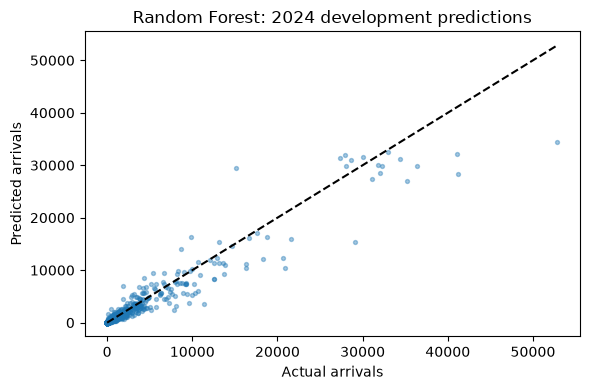

In [6]:
results = validation_data[['Month', 'Country', 'Arrivals', 'lag_1']].copy()
results['Prediction'] = predict_arrivals(validation_data)
results['Error'] = np.abs(results.Arrivals - results.Prediction)
results['Baseline_error'] = np.abs(results.Arrivals - results.lag_1)

market_errors = results.groupby('Country').agg(
    actual=('Arrivals', 'sum'), MAE=('Error', 'mean'), baseline_MAE=('Baseline_error', 'mean'))
print('Origins beating the previous-month baseline:',
      int((market_errors.MAE < market_errors.baseline_MAE).sum()), '/', len(market_errors))
display(market_errors.sort_values('actual', ascending=False).head(10).round(2))

plt.figure(figsize=(6, 4))
plt.scatter(results.Arrivals, results.Prediction, s=8, alpha=.4)
limit = max(results.Arrivals.max(), results.Prediction.max())
plt.plot([0, limit], [0, limit], 'k--')
plt.xlabel('Actual arrivals')
plt.ylabel('Predicted arrivals')
plt.title(f'{chosen_name}: 2024 development predictions')
plt.tight_layout()
plt.show()

## SHAP explanations
I use training rows as background and explain 40 sampled validation cases. For the local example, I choose the first validation month for the largest training market without checking its error first. Country codes let the explainers pass numeric arrays; the model still receives country names.

PermutationExplainer explainer:  63%|██████▎   | 26/41 [00:00<?, ?it/s]

PermutationExplainer explainer:  68%|██████▊   | 28/41 [00:10<00:02,  6.11it/s]

PermutationExplainer explainer:  71%|███████   | 29/41 [00:10<00:03,  3.93it/s]

PermutationExplainer explainer:  73%|███████▎  | 30/41 [00:11<00:03,  3.43it/s]

PermutationExplainer explainer:  76%|███████▌  | 31/41 [00:11<00:02,  3.33it/s]

...

PermutationExplainer explainer:  95%|█████████▌| 39/41 [00:14<00:00,  2.46it/s]

PermutationExplainer explainer:  98%|█████████▊| 40/41 [00:15<00:00,  2.49it/s]

PermutationExplainer explainer: 100%|██████████| 41/41 [00:15<00:00,  2.50it/s]

PermutationExplainer explainer: 42it [00:15,  2.50it/s]                        

PermutationExplainer explainer: 42it [00:15,  1.01it/s]

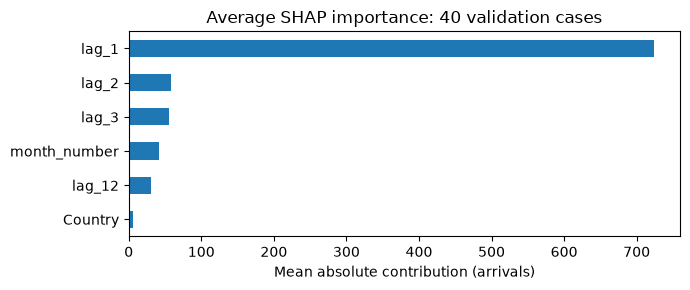

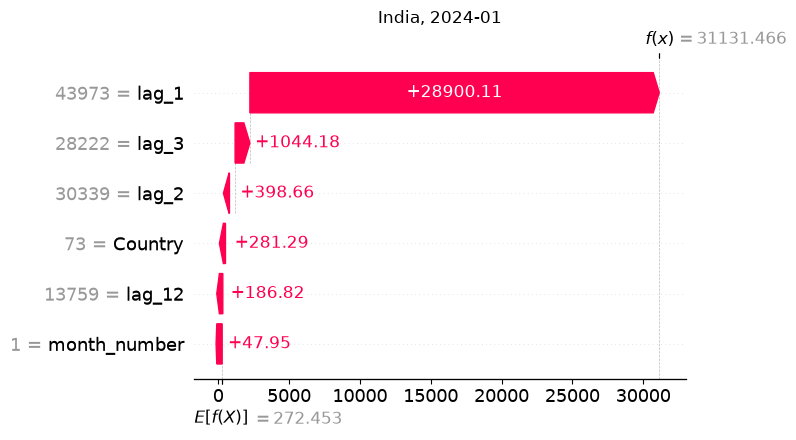

SHAP sum: 31131.47 | model: 31131.47 | gap: 0.0


In [7]:
import shap
from lime.lime_tabular import LimeTabularExplainer

countries = sorted(train_data.Country.unique())
country_codes = {country: index for index, country in enumerate(countries)}

def encode(frame):
    values = frame[features].copy()
    values['Country'] = values.Country.map(country_codes)
    return values.to_numpy(dtype=float)

# I turn the country codes back into names before calling the model.
def explain_prediction(array):
    frame = pd.DataFrame(np.atleast_2d(array), columns=features)
    frame['Country'] = [countries[index] for index in np.rint(frame.Country).astype(int)]
    return predict_arrivals(frame)

# Background rows come from training, not the cases being explained.
background = encode(train_data.sample(40, random_state=random_seed))
largest_market = train_data.groupby('Country').Arrivals.sum().idxmax()
example = validation_data.loc[validation_data.Country.eq(largest_market)].head(1)
sample = validation_data.sample(40, random_state=random_seed)
explanation_rows = pd.concat([example, sample]).drop_duplicates(['Month', 'Country'])

explainer = shap.Explainer(explain_prediction, shap.maskers.Independent(background),
                           algorithm='permutation', feature_names=features, seed=random_seed)
shap_values = explainer(encode(explanation_rows), max_evals=65)
importance = pd.Series(np.abs(shap_values.values[1:]).mean(axis=0), index=features).sort_values()
importance.plot.barh(figsize=(7, 3), title='Average SHAP importance: 40 validation cases')
plt.xlabel('Mean absolute contribution (arrivals)')
plt.tight_layout()
plt.show()

shap.plots.waterfall(shap_values[0], max_display=len(features), show=False)
plt.title(f'{example.Country.iloc[0]}, {example.Month.iloc[0]}')
plt.tight_layout()
plt.show()
model_prediction = float(predict_arrivals(example)[0])
shap_prediction = float(shap_values.base_values[0] + shap_values.values[0].sum())
print('SHAP sum:', round(shap_prediction, 2), '| model:', round(model_prediction, 2),
      '| gap:', round(abs(shap_prediction - model_prediction), 3))

## LIME for the same example
LIME fits a simple model near this prediction. Its local R² and prediction gap show how closely it matches the forest. Both explainers use the selected predictor. Neither establishes cause and effect, and changing related lags separately can create unrealistic inputs.

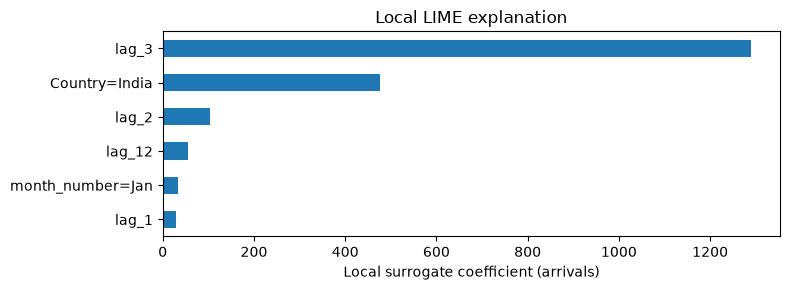

Local surrogate R²: 0.699
Surrogate prediction: 30352.58 | model: 31131.47 | gap: -778.88


In [8]:
month_names = ['unused', 'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
month_column = features.index('month_number')
lime_explainer = LimeTabularExplainer(
    encode(train_data), feature_names=features, mode='regression',
    categorical_features=[0, month_column], categorical_names={0: countries, month_column: month_names},
    discretize_continuous=False, sample_around_instance=True,
    kernel_width=1.0, random_state=random_seed)
lime_result = lime_explainer.explain_instance(
    encode(example)[0], explain_prediction, num_features=len(features), num_samples=3000)

weights = pd.Series(dict(lime_result.as_list())).sort_values()
weights.plot.barh(figsize=(8, 3), color=['tab:red' if weight < 0 else 'tab:blue' for weight in weights])
plt.axvline(0, color='black', linewidth=.7)
plt.title('Local LIME explanation')
plt.xlabel('Local surrogate coefficient (arrivals)')
plt.tight_layout()
plt.show()

# I check the approximation instead of assuming LIME matches the forest.
print('Local surrogate R²:', round(float(lime_result.score), 3))
print('Surrogate prediction:', round(float(lime_result.local_pred[0]), 2),
      '| model:', round(model_prediction, 2),
      '| gap:', round(float(lime_result.local_pred[0] - model_prediction), 2))

For India in January 2024, the forest predicts **31,131** arrivals; the actual count is **34,399**. Previous-month arrivals has the largest SHAP contribution, about **+28,900** relative to the training background. The contributions sum to the prediction.

LIME gives a local R² of **0.699** and a prediction about **779** arrivals below the forest. It gives a useful but imperfect local explanation. Its coefficients describe nearby changes, while SHAP compares the case with the background data.

## Prediction example
This 2024 example shows the inputs and output. To estimate a future month, I would need the same historical counts for an origin seen during training.

In [9]:
display(example[features])
display(pd.DataFrame({
    'Month': [str(example.Month.iloc[0])], 'Country': [example.Country.iloc[0]],
    'Predicted_arrivals': [round(float(predict_arrivals(example)[0]))],
    'Observed_arrivals': [int(example.Arrivals.iloc[0])]}))

,Country,lag_1,lag_2,lag_3,lag_12,month_number
10883,India,43973,30339,28222,13759,1


,Month,Country,Predicted_arrivals,Observed_arrivals
0,2024-01,India,31131,34399


## Limitations
These are development results, not an independent final test. The forest beats last month's baseline for **103 of 184 origins**, so improvement is uneven. Market size and shared disruptions also affect the overall scores.

Air capacity, exchange rates and travel restrictions are not included. Predictions depend on published historical counts, which can arrive late or be revised. A prediction interval is not available.